# Dar_017 — Comparable lunar environmental profiles for base-location assessment

**Question:** What supported environmental differences and evidence gaps distinguish the seven original regions, alongside their terrain context?

Uses accepted Dar_012 center/phase exports. Exact CNN-patch matching is optional. These profiles prepare rule inputs, not a completed suitability ranking. [Plan](../../EDA_Notes.md) / [results](../../EDA_Notes.md).

In [1]:
from pathlib import Path
import sys,json
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0]=[str(ROOT / "darrel stuff/EDA/shared"), str(ROOT / "darrel stuff/EDA/Moon/Stage3_Requirements"),str(ROOT)]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from environment_workflow import LocalRun as Run,latest_completed_run
from decision_eda import accepted_input,CONTEXT
from site_comparison import (COHORTS,cohort_rows,static_profiles,thermal_profiles,joint_state,joint_sweep,
    thermal_joint_summary,rule_input_table)
import decision_eda,site_comparison
def short(value):return value.split('_',2)[-1].replace('_',' ')
def savefig(run,fig,name):
    fig.savefig(run.path(name+'.png'),dpi=140,bbox_inches='tight');display(fig);plt.close(fig)
def findings(run,record):
    run.path('findings.json').write_text(json.dumps(record,indent=2,default=str),encoding='utf-8');display(record)


## Comparison design
- Static distributions count each distinct regional observed center once, not once per phase. Available, positive-LOLA-spot and complete-common cohorts remain separate. Positive spots are a sensitivity cohort, not an adopted quality policy.
- Thermal comparisons use the same common source products. Products receive equal weight; they are phase bins, not equally spaced mission dates. Fixed-common cohorts are absent in three regions and remain undefined there.
- Quantile ranges describe spatial/phase variation, not confidence intervals, exposure extrema or equipment temperatures.
- Keep source units, native resolution/support and the technical-lookup/physical-registration limitation. No source or threshold is fabricated to make every region comparable.

Accepted local analysis/dar_012_joint_environment run: 20261106T134155791814Z_c6f9ab


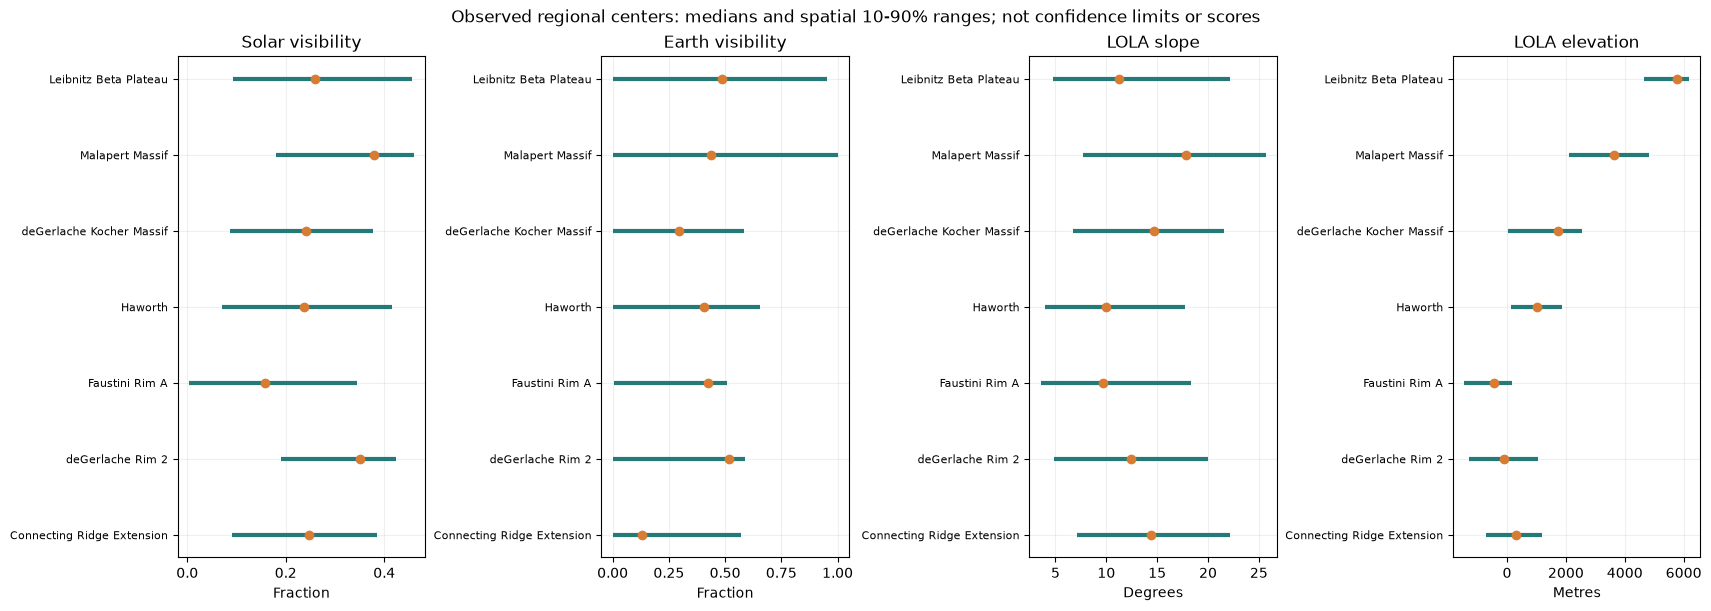

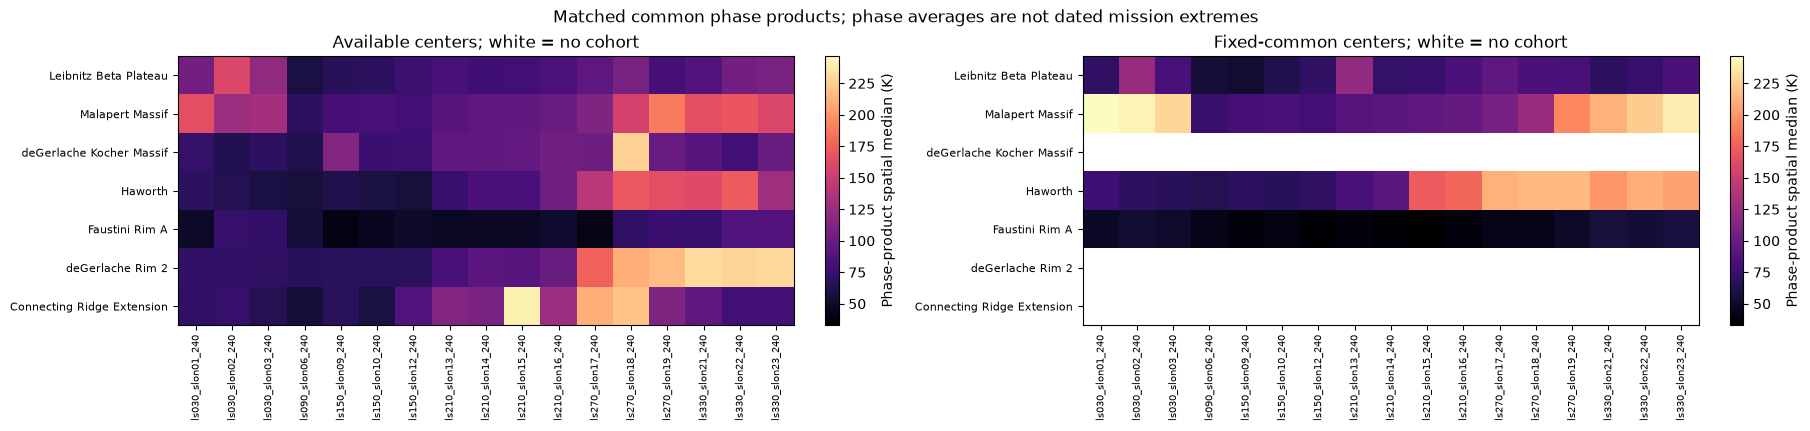

{'regions': 7,
 'observed_centers': 55380,
 'common_products': 17,
 'profile_rows': 189,
 'thermal_profile_rows': 14,
 'regions_without_fixed_common_centers': ['A3CLR22_12_deGerlache_Kocher_Massif',
  'A3CLR22_4_deGerlache_Rim_2',
  'A3CLR22_5_Connecting_Ridge_Extension'],
 'observed_center_medians': [{'region': 'A3CLR22_10_Leibnitz_Beta_Plateau',
   'median_solar_visibility': 0.26012,
   'median_earth_visibility': 0.4852,
   'median_slope_deg': 11.293517589569092,
   'median_of_product_medians_K': 84.727314,
   'span_of_product_medians_K': 100.16167850000001},
  {'region': 'A3CLR22_11_Malapert_Massif',
   'median_solar_visibility': 0.37984,
   'median_earth_visibility': 0.43772,
   'median_slope_deg': 17.788856506347656,
   'median_of_product_medians_K': 110.672676,
   'span_of_product_medians_K': 117.937019},
  {'region': 'A3CLR22_12_deGerlache_Kocher_Massif',
   'median_solar_visibility': 0.24072,
   'median_earth_visibility': 0.29436,
   'median_slope_deg': 14.690350532531738,
   '

,region,median_earth_visibility,median_effective_resolution_m,median_elevation_error_m,median_elevation_m,median_permanent_shadow,median_sky_view_sr,median_slope_deg,median_solar_visibility,median_spot_count,observed_centers,fixed_common_centers,zero_spot_centers,zero_spot_fraction,fixed_common_fraction,supported_common_products,median_of_product_medians_K,span_of_product_medians_K,grain,base_suitability_status
0,A3CLR22_10_Leibnitz_Beta_Plateau,0.48520,18.711585,0.139452,5763.168701,0.0,5.8422,11.293518,0.26012,4.0,4422,84,243,0.054953,0.018996,17,84.727314,100.161679,regional observed-center union; equal-product ...,Unknown: no configured mission/policy
1,A3CLR22_11_Malapert_Massif,0.43772,15.711732,0.123132,3628.888672,0.0,5.6818,17.788857,0.37984,6.0,7569,6051,174,0.022989,0.799445,17,110.672676,117.937019,regional observed-center union; equal-product ...,Unknown: no configured mission/policy
2,A3CLR22_12_deGerlache_Kocher_Massif,0.29436,24.406695,0.225091,1730.998474,0.0,5.7162,14.690351,0.24072,2.0,6972,0,1163,0.166810,0.000000,17,94.805915,163.976033,regional observed-center union; equal-product ...,Unknown: no configured mission/policy
3,A3CLR22_2_Haworth,0.40730,15.077662,0.119683,1031.073181,0.0,5.8208,9.994444,0.23756,7.0,15500,2510,216,0.013935,0.161935,17,83.077610,116.295196,regional observed-center union; equal-product ...,Unknown: no configured mission/policy
4,A3CLR22_3_Faustini_Rim_A,0.42504,21.267061,0.169069,-437.535156,0.0,5.8334,9.635665,0.15838,3.0,6972,15,557,0.079891,0.002151,17,51.435951,47.805477,regional observed-center union; equal-product ...,Unknown: no configured mission/policy
5,A3CLR22_4_deGerlache_Rim_2,0.51756,17.471346,0.132705,-102.810295,0.0,5.7954,12.405789,0.35024,5.0,6889,0,226,0.032806,0.000000,17,90.302116,164.525875,regional observed-center union; equal-product ...,Unknown: no configured mission/policy
6,A3CLR22_5_Connecting_Ridge_Extension,0.12952,19.718483,0.144929,291.800766,0.0,5.6182,14.414321,0.24760,3.0,7056,0,522,0.073980,0.000000,17,88.384842,185.012293,regional observed-center union; equal-product ...,Unknown: no configured mission/policy


,region,cohort,common_products,supported_common_products,median_of_product_medians_K,minimum_product_median_K,maximum_product_median_K,span_of_product_medians_K,minimum_centers_per_supported_product,maximum_centers_per_supported_product,aggregation,evidence_status
0,A3CLR22_10_Leibnitz_Beta_Plateau,available,17,17,84.727314,58.984043,159.145722,100.161679,1280.0,4422.0,"equal product weight; phase-average summaries,...",supported
1,A3CLR22_10_Leibnitz_Beta_Plateau,fixed_common,17,17,74.857238,52.361503,124.537632,72.176129,84.0,84.0,"equal product weight; phase-average summaries,...",supported
2,A3CLR22_11_Malapert_Massif,available,17,17,110.672676,69.412819,187.349838,117.937019,7144.0,7569.0,"equal product weight; phase-average summaries,...",supported
3,A3CLR22_11_Malapert_Massif,fixed_common,17,17,107.061409,74.772491,246.717178,171.944687,6051.0,6051.0,"equal product weight; phase-average summaries,...",supported
4,A3CLR22_12_deGerlache_Kocher_Massif,available,17,17,94.805915,61.929057,225.905090,163.976033,15.0,6972.0,"equal product weight; phase-average summaries,...",supported
5,A3CLR22_12_deGerlache_Kocher_Massif,fixed_common,17,0,NaN,NaN,NaN,NaN,NaN,NaN,"equal product weight; phase-average summaries,...",no_complete_common_cohort
6,A3CLR22_2_Haworth,available,17,17,83.077610,56.615555,172.910751,116.295196,11122.0,14646.0,"equal product weight; phase-average summaries,...",supported
7,A3CLR22_2_Haworth,fixed_common,17,17,91.880443,64.342338,215.332016,150.989678,2510.0,2510.0,"equal product weight; phase-average summaries,...",supported
8,A3CLR22_3_Faustini_Rim_A,available,17,17,51.435951,39.655147,87.460625,47.805477,24.0,6972.0,"equal product weight; phase-average summaries,...",supported
9,A3CLR22_3_Faustini_Rim_A,fixed_common,17,17,42.547775,32.885864,57.541164,24.655300,15.0,15.0,"equal product weight; phase-average summaries,...",supported


Completed: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data\processed\analysis\dar_017_lunar_site_profiles\20261109T142722168673Z_e95126


In [2]:
REGION_LIMIT=None  # Use 1 for a representative first execution, None for all seven regions.
JOINT_RUN_ID='20261106T134155791814Z_c6f9ab'
joint=latest_completed_run(ROOT,'analysis/dar_012_joint_environment',JOINT_RUN_ID)
variables={'solar_visibility':'fraction','earth_visibility':'fraction','permanent_shadow':'binary',
    'sky_view_sr':'steradian','elevation_m':'m; 1737400 m radius reference','slope_deg':'degree',
    'elevation_error_m':'m','effective_resolution_m':'m','spot_count':'count'}
with Run(ROOT,'analysis/dar_017_lunar_site_profiles',{'joint_run':str(joint.relative_to(ROOT)),
    'region_limit':REGION_LIMIT,'scope':'regional observed-center profiles and equal-product thermal summaries',
    'mission_ranking':False},'Moon/Site_Assessment/Dar_017_lunar_base_environment_profiles.ipynb') as run:
    run.input(Path(site_comparison.__file__));run.input(Path(decision_eda.__file__))
    centers=pd.read_csv(accepted_input(run,joint,'native_center_context.csv.gz'))
    regional=pd.read_csv(accepted_input(run,joint,'region_phase_features.csv'))
    source_contract=json.loads(accepted_input(run,joint,'feature_contract.json').read_text())
    regions=sorted(centers.region.unique())
    if REGION_LIMIT is not None:
        if type(REGION_LIMIT) is not int or not 1<=REGION_LIMIT<=len(regions):raise ValueError('Invalid region sample')
        regions=regions[:REGION_LIMIT]
    centers=centers.loc[centers.region.isin(regions)].copy();regional=regional.loc[regional.region.isin(regions)].copy()
    products=sorted(regional.loc[regional.common_product,'source_product'].unique())
    if not products:raise ValueError('No supported common source products')
    profiles=static_profiles(centers,variables);thermal=thermal_profiles(regional)
    profiles.to_csv(run.path('regional_static_profiles.csv'),index=False)
    thermal.to_csv(run.path('common_product_thermal_profiles.csv'),index=False)
    regional.loc[regional.common_product].to_csv(run.path('common_product_detail.csv'),index=False)
    coverage=centers.groupby('region').agg(observed_centers=('clon','size'),
        fixed_common_centers=('complete_common_cohort','sum'),zero_spot_centers=('spot_count',lambda x:x.eq(0).sum()))
    coverage['zero_spot_fraction']=coverage.zero_spot_centers/coverage.observed_centers
    coverage['fixed_common_fraction']=coverage.fixed_common_centers/coverage.observed_centers
    coverage.to_csv(run.path('region_support.csv'))
    comparison=profiles.loc[profiles.cohort.eq('available')].pivot(index='region',columns='variable',values='median').add_prefix('median_')
    comparison=comparison.join(coverage).join(thermal.loc[thermal.cohort.eq('available')].set_index('region')[
        ['supported_common_products','median_of_product_medians_K','span_of_product_medians_K']]).reset_index()
    comparison['grain']='regional observed-center union; equal-product thermal summary'
    comparison['base_suitability_status']='Unknown: no configured mission/policy'
    comparison.to_csv(run.path('seven_region_environment_comparison.csv'),index=False)
    available=profiles.loc[profiles.cohort.eq('available'),['region','variable','median']].rename(columns={'median':'available_median'})
    sensitivity=profiles.loc[profiles.cohort.ne('available')].merge(available,on=['region','variable'],validate='many_to_one')
    sensitivity['median_minus_available']=sensitivity['median']-sensitivity.available_median
    sensitivity.to_csv(run.path('static_cohort_sensitivity.csv'),index=False)
    fig,axes=plt.subplots(1,4,figsize=(17,6),layout='constrained')
    for ax,variable,title,unit in zip(axes,['solar_visibility','earth_visibility','slope_deg','elevation_m'],
        ['Solar visibility','Earth visibility','LOLA slope','LOLA elevation'],['Fraction','Fraction','Degrees','Metres']):
        p=profiles.loc[profiles.variable.eq(variable)&profiles.cohort.eq('available')].set_index('region').loc[regions]
        ax.hlines(range(len(regions)),p.q10,p.q90,color='#237a78',lw=3)
        ax.scatter(p['median'],range(len(regions)),color='#d77c32',zorder=3)
        ax.set_yticks(range(len(regions)),[short(x) for x in regions],fontsize=8);ax.invert_yaxis()
        ax.set(title=title,xlabel=unit);ax.grid(alpha=.2)
    fig.suptitle('Observed regional centers: medians and spatial 10-90% ranges; not confidence limits or scores')
    savefig(run,fig,'regional_environment_profiles')
    fig,axes=plt.subplots(1,2,figsize=(18,max(4,len(regions)*.6)),layout='constrained')
    common=regional.loc[regional.common_product]
    for ax,value,title in zip(axes,['tbol_median_K','fixed_common_tbol_median_K'],['Available centers','Fixed-common centers']):
        matrix=common.pivot(index='region',columns='source_product',values=value).reindex(index=regions,columns=products)
        finite=common[['tbol_median_K','fixed_common_tbol_median_K']].to_numpy();finite=finite[np.isfinite(finite)]
        im=ax.imshow(matrix,aspect='auto',vmin=finite.min(),vmax=finite.max(),cmap='magma')
        ax.set_yticks(range(len(regions)),[short(x) for x in regions],fontsize=8)
        ax.set_xticks(range(len(products)),[x.replace('pcp_avg_tbol_pols_','') for x in products],rotation=90,fontsize=7)
        ax.set_title(title+'; white = no cohort');fig.colorbar(im,ax=ax,label='Phase-product spatial median (K)')
    fig.suptitle('Matched common phase products; phase averages are not dated mission extremes')
    savefig(run,fig,'common_product_temperature_profiles')
    contract={'source_contract':source_contract,'variables':variables,'common_products':products,
        'static_grain':'one vote per distinct observed regional center',
        'thermal_grain':'equal weight over matched source-product medians, not calendar time',
        'cohorts':list(COHORTS),'excluded':['unfinished slope-error map'],
        'not_claimed':['full-area coverage','physical co-registration','base eligibility','preference weights']}
    run.path('comparison_contract.json').write_text(json.dumps(contract,indent=2),encoding='utf-8')
    findings(run,{'regions':len(regions),'observed_centers':len(centers),'common_products':len(products),
        'profile_rows':len(profiles),'thermal_profile_rows':len(thermal),
        'regions_without_fixed_common_centers':coverage.index[coverage.fixed_common_centers.eq(0)].tolist(),
        'observed_center_medians':comparison[['region','median_solar_visibility','median_earth_visibility','median_slope_deg',
            'median_of_product_medians_K','span_of_product_medians_K']].to_dict('records'),
        'ranking_computed':False,'limits':['Sampled-center context is not a whole-region land-area statistic',
            'Equal-product summaries are not mission-duration averages','No universal better/safer direction or weights inferred']})
    display(comparison);display(thermal)
OUT=run.directory;print('Completed:',OUT)


## Pipeline use
Use the comparison table to identify trade-offs and the coverage/cohort evidence needed by proposed environmental criteria. Do not equate a high regional illumination median and a low slope elsewhere with a jointly suitable site. Dar_018 tests co-location directly. No weights or mandatory limits are learned from these regional summaries.